# Core CPI — One-Month-Ahead Forecast

**Target:** month-over-month % change in CPI All items less food and energy, seasonally adjusted (FRED `CPILFESL`).

**What this notebook does**
1. Pulls core CPI, its main building blocks and a set of leading indicators live. FRED, the BLS public API,
   Apartment List, Zillow and Cox Automotive (Manheim) need no key.
2. Fills in the missing October 2025 index (government shutdown) as `sqrt(Sep 2025 × Nov 2025)`.
   The same geometric-mean fill is applied to every CPI block.
3. Builds a real-time information set. Each predictor enters only with the lag at which it is actually published.
4. Backtests **top-down** models (forecast core CPI directly) and **bottom-up** models (forecast 9 blocks
   and aggregate). Every model is refit monthly in a recursive pseudo-out-of-sample exercise.
   * **Time series:** naive means, AR(BIC), ARMA, local level, ARX, Huber-robust ARX and a factor-augmented AR.
   * **Machine learning:** Ridge, Lasso, Random Forest and XGBoost on a long and a short feature set.
   * **Hybrids:** ARX plus ML fitted to the ARX residuals.
   * **Bottom-up**, three variants:
     * AR for every block.
     * **Tailored** block models: the specifications that won in the OER, rent, lodging and core-goods
       notebooks, plus jet fuel for transportation services.
     * Ridge for every block.
   * **Combinations:** mean, median, trimmed mean, inverse-MSE, top-5 and constrained stacking.
5. Scores everything, picks a headline model by a robustness rule, and produces the next-month forecast
   with a block-by-block breakdown.

**Core CPI structure (approximate shares of core):**
* Shelter, about 45%: OER about 33%, rent about 9%, lodging about 2%.
* Core goods, about 25%.
* Services excluding shelter ("supercore"), about 30%: medical care, transportation, education &
  communication, recreation, water/sewer/trash, and others.

**Shutdown distortions.**
* Oct and Nov 2025 come out at about 0.10% each after the imputation and are excluded from scoring.
* April 2026 (0.38%) contains the shelter catch-up: the October-2025 rent panel was repriced against April 2025.
* When `CLEAN_DISTORTIONS=True`, the OER and rent block inputs are cleaned as in those notebooks (backward
  3-month mean). Core CPI's own inputs are cleaned by subtracting the shelter distortion, weighted by
  shelter's share of core. Published values are always used for scoring.

In [1]:
# ---------------------------------------------------------------- configuration
import warnings, re, io, time, os, html as htmlmod
from datetime import date

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from scipy import stats
from scipy.optimize import nnls
import statsmodels.api as sm
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV, LassoCV, HuberRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 40)

TARGET_ID         = "CPILFESL"
TRAIN_START       = "2003-01-01"   # first target month used for estimation (long-history models)
BACKTEST_START    = "2014-01-01"   # first pseudo-out-of-sample forecast (2014 = burn-in for combination weights)
SCORE_START       = "2015-01-01"   # long-history evaluation window
SCORE_START_ALL   = "2021-01-01"   # window that also includes the short-history (market-rent) models
EXCLUDE_FROM_SCORE = ["2025-10-01", "2025-11-01"]
DISTORTED_MONTHS  = ["2025-10-01", "2025-11-01", "2026-04-01"]
CLEAN_DISTORTIONS = True
SHELTER_SHARE_OF_CORE = {"OER": 0.33, "Rent": 0.093}   # approx. relative importance / core weight, used to clean core
MIN_TRAIN_OBS     = 30
HALF_LIFE         = 36
N_FACTORS         = 4
BU_WEIGHT_WINDOW  = 60
COMBO_LOOKBACK    = 24
STACK_LOOKBACK    = 36
BAND_START        = "2023-01-01"   # uncertainty band uses post-2022 errors
USE_MANHEIM_MIDMONTH_PROXY = True
MANHEIM_LOCAL_FILE = "manheim.xlsx"
BLS_API_KEY       = None
CACHE_DIR         = "data_cache"
BENCH, NAIVE      = "AR (BIC)", "Mean 3m"
SEED              = 42
BROWSER = {"User-Agent": "Mozilla/5.0"}   # Cox / Apartment List need a browser UA; FRED stalls on one

PAL = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100",
       "magenta": "#e87ba4", "green": "#008300", "violet": "#6250d6", "red": "#e34948",
       "ink": "#0b0b0b", "ink2": "#52514e", "muted": "#8a8984", "grid": "#e4e3df"}
FAMILY_COLOR = {"Time series": PAL["blue"], "Machine learning": PAL["orange"], "Hybrid": PAL["aqua"],
                "Bottom-up": PAL["yellow"], "Combination": PAL["violet"]}
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": PAL["muted"], "axes.labelcolor": PAL["ink2"], "axes.titlecolor": PAL["ink"],
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": PAL["grid"], "grid.linewidth": 0.8,
    "xtick.color": PAL["ink2"], "ytick.color": PAL["ink2"], "lines.linewidth": 1.6,
    "legend.frameon": False, "font.size": 10,
})
os.makedirs(CACHE_DIR, exist_ok=True)

## 1. Data

| Series | Source | Transform | Publication lag used* |
|---|---|---|---|
| Core CPI, SA (`CPILFESL`) | BLS via FRED | m/m % | 1 |
| Blocks (SA): OER, rent, lodging, core goods, medical care services, transportation services, water/sewer/trash (FRED); education & communication services, recreation services (BLS API) | BLS | m/m % | 1 |
| Manheim Used Vehicle Value Index (SA) | Cox Automotive (history file plus releases) | m/m % | 0 |
| PPI final demand goods less food & energy (`WPSFD4131`) | BLS via FRED | m/m % | 1 |
| Case-Shiller national HPI (`CSUSHPISA`) | FRED | y/y % | 2 |
| CPI all items less shelter (`CUSR0000SA0L2`) | BLS via FRED | y/y % | 1 |
| Avg hourly earnings, private (`CES0500000003`); unemployment rate (`UNRATE`) | BLS jobs report via FRED | y/y %, 3m ann.; level, 12m change | 0 |
| Jet fuel (`DJFUELUSGULF`), WTI (`DCOILWTICO`), daily | EIA via FRED | monthly avg, m/m % | 0 |
| Philadelphia Fed manufacturing prices paid | FRED | diffusion index | 0 |
| Apartment List rent index and vacancy; Zillow ZORI | apartmentlist.com; zillow.com | y/y % | 0; 1 |

\*Months between the data month and the target month, for a forecast made just before the CPI release for month *T*.
A lag-0 series not yet published when the notebook runs is dropped from the live forecast.

**Feature sets.** **A (2008+):** core and block lags plus all FRED/Manheim indicators.
**B (2018+):** A plus Apartment List, Zillow and the two BLS-API service blocks.

In [2]:
def fred(series_id: str) -> pd.Series:
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"
    for attempt in range(3):
        try:
            r = requests.get(url, timeout=60); r.raise_for_status(); break
        except Exception:
            if attempt == 2: raise
            time.sleep(2)
    df = pd.read_csv(io.StringIO(r.text))
    s = pd.to_numeric(df.iloc[:, 1], errors="coerce")
    s.index = pd.to_datetime(df.iloc[:, 0]); s.name = series_id
    return s


def bls(series_ids, start_year=2005) -> pd.DataFrame:
    cache = os.path.join(CACHE_DIR, f"bls_{'_'.join(series_ids)}_{date.today():%Y%m%d}.csv")
    if os.path.exists(cache):
        return pd.read_csv(cache, index_col=0, parse_dates=True)
    span = 20 if BLS_API_KEY else 10
    url = f"https://api.bls.gov/publicAPI/{'v2' if BLS_API_KEY else 'v1'}/timeseries/data/"
    rows, y0 = [], start_year
    while y0 <= date.today().year:
        payload = {"seriesid": list(series_ids), "startyear": str(y0), "endyear": str(min(y0 + span - 1, date.today().year))}
        if BLS_API_KEY:
            payload["registrationkey"] = BLS_API_KEY
        j = requests.post(url, json=payload, timeout=60).json()
        if j.get("status") != "REQUEST_SUCCEEDED":
            raise RuntimeError(f"BLS API: {j.get('status')} {j.get('message')}")
        for s in j["Results"]["series"]:
            for d in s["data"]:
                if d["period"].startswith("M") and d["period"] != "M13":
                    rows.append((s["seriesID"], pd.Timestamp(int(d["year"]), int(d["period"][1:]), 1),
                                 pd.to_numeric(d["value"], errors="coerce")))
        y0 += span
    out = pd.DataFrame(rows, columns=["id", "date", "v"]).pivot_table(index="date", columns="id", values="v").sort_index()
    out.to_csv(cache)
    return out


def manheim():
    """Manheim index: history xlsx (local file or site.manheim.com) extended with Cox monthly / mid-month releases."""
    src, hist = [], pd.Series(dtype=float)
    try:
        if os.path.exists(MANHEIM_LOCAL_FILE):
            x = pd.read_excel(MANHEIM_LOCAL_FILE, sheet_name="DATA", header=0, index_col=0); src.append("local file")
        else:
            page = requests.get("https://site.manheim.com/en/services/consulting/used-vehicle-value-index.html",
                                headers=BROWSER, timeout=60).text
            link = sorted(set(re.findall(r'https://site\.manheim\.com/wp-content/uploads/[^"]+Used-Vehicle-Value-Index\.xlsx', page)))[-1]
            x = pd.read_excel(io.BytesIO(requests.get(link, headers=BROWSER, timeout=60).content),
                              sheet_name="DATA", header=0, index_col=0); src.append(link.rsplit("/", 1)[-1])
        hist = x.iloc[:, 0].astype(float)
        hist.index = pd.to_datetime(hist.index).to_period("M").to_timestamp()
    except Exception as e:
        print("Manheim history file unavailable:", e)
    full, mid = {}, {}
    for page_no in (1, 2, 3):
        r = requests.get("https://www.coxautoinc.com/wp-json/wp/v2/insight",
                         params={"search": "Manheim Used Vehicle Value Index", "per_page": 50, "page": page_no,
                                 "_fields": "title,content"}, headers=BROWSER, timeout=60)
        if r.status_code != 200 or not r.json():
            break
        for p in r.json():
            title = htmlmod.unescape(p["title"]["rendered"])
            m = re.search(r"Value Index:\s*(Mid-)?([A-Za-z]+)\s+(\d{4})\s+Trends", title)
            if not m:
                continue
            body = re.sub(r"\s+", " ", htmlmod.unescape(re.sub(r"<[^>]+>", " ", p["content"]["rendered"])))
            v = re.search(r"\(MUVVI\)[^0-9]{0,80}?(\d{3}(?:\.\d+)?)", body)
            if not v:
                continue
            try:
                month = pd.to_datetime(f"1 {m.group(2)[:3]} {m.group(3)}", format="%d %b %Y")
            except ValueError:
                continue
            (mid if m.group(1) else full)[month] = float(v.group(1))
    src.append(f"{len(full)} monthly + {len(mid)} mid-month Cox releases")
    full = pd.Series(full).sort_index()
    s = pd.concat([hist, full[~full.index.isin(hist.index)]]).sort_index()
    return s.rename("manheim"), pd.Series(mid).sort_index().rename("manheim_mid"), "; ".join(src)


def apartment_list():
    page = requests.get("https://www.apartmentlist.com/research/category/data-rent-estimates", headers=BROWSER, timeout=60).text
    links = sorted(set(re.findall(r'//assets\.ctfassets\.net/[^"\s]+?\.csv', page)))
    def pick(pattern):
        c = [l for l in links if re.search(pattern, l)]
        if not c:
            raise RuntimeError(f"Apartment List file {pattern} not found")
        return "https:" + sorted(c)[-1]
    def national(url, bed=None):
        d = pd.read_csv(io.StringIO(requests.get(url, headers=BROWSER, timeout=60).text))
        d = d[d["location_type"].eq("National")]
        if bed is not None:
            d = d[d["bed_size"].eq(bed)]
        cols = [c for c in d.columns if re.fullmatch(r"\d{4}_\d{2}", c)]
        s = d[cols].iloc[0].astype(float)
        s.index = pd.to_datetime([c.replace("_", "-") + "-01" for c in cols])
        return s
    return (national(pick(r"Apartment_List_Rent_Estimates_\d{4}_\d{2}\.csv"), "overall").rename("al_rent"),
            national(pick(r"Apartment_List_Vacancy_Index_\d{4}_\d{2}\.csv")).rename("al_vac"))


def zillow_zori():
    url = "https://files.zillowstatic.com/research/public_csvs/zori/Metro_zori_uc_sfrcondomfr_sm_sa_month.csv"
    d = pd.read_csv(io.StringIO(requests.get(url, headers=BROWSER, timeout=60).text))
    row = d[d["RegionName"].eq("United States")].iloc[0]
    cols = [c for c in d.columns if re.fullmatch(r"\d{4}-\d{2}-\d{2}", c)]
    s = row[cols].astype(float)
    s.index = pd.to_datetime(cols).to_period("M").to_timestamp()
    return s.rename("zori")


BLOCKS = {   # name: (series id, source)
    "OER": ("CUSR0000SEHC", "fred"), "Rent": ("CUSR0000SEHA", "fred"), "Lodging": ("CUSR0000SEHB", "fred"),
    "Core goods": ("CUSR0000SACL1E", "fred"), "Medical services": ("CUSR0000SAM2", "fred"),
    "Transportation services": ("CUSR0000SAS4", "fred"), "Water/sewer/trash": ("CUSR0000SEHG", "fred"),
    "Educ. & comm. services": ("CUSR0000SAES", "bls"), "Recreation services": ("CUSR0000SARS", "bls"),
}
FRED_IDS = {"core": TARGET_ID, "ppi_cg": "WPSFD4131", "cs": "CSUSHPISA", "exshelter": "CUSR0000SA0L2",
            "ahe": "CES0500000003", "unrate": "UNRATE", "jet": "DJFUELUSGULF", "wti": "DCOILWTICO",
            "philly_pp": "PPCDFSA066MSFRBPHI"}

raw = {k: fred(sid) for k, sid in FRED_IDS.items()}
for k in ("jet", "wti"):
    raw[k] = raw[k].resample("MS").mean()
bls_df = bls([sid for sid, src in BLOCKS.values() if src == "bls"])
for name, (sid, src) in BLOCKS.items():
    raw[f"b:{name}"] = fred(sid) if src == "fred" else bls_df[sid]
raw["manheim"], manheim_mid, mh_src = manheim()
raw["al_rent"], raw["al_vac"] = apartment_list()
raw["zori"] = zillow_zori()

data = pd.DataFrame(raw).sort_index().loc["1997-01-01":]
data.index = pd.DatetimeIndex(data.index).to_period("M").to_timestamp()
data = data.groupby(level=0).last()
print("Manheim sources:", mh_src)
print(pd.DataFrame({"first": data.apply(lambda s: s.first_valid_index().date()),
                    "last":  data.apply(lambda s: s.last_valid_index().date())}))

Manheim sources: Nov-2025-Manheim-Used-Vehicle-Value-Index.xlsx; 11 monthly + 12 mid-month Cox releases
                                first        last
core                       1997-01-01  2026-09-01
ppi_cg                     1997-01-01  2026-09-01
cs                         1997-01-01  2026-08-01
exshelter                  1997-01-01  2026-09-01
ahe                        2006-03-01  2026-09-01
unrate                     1997-01-01  2026-09-01
jet                        1997-01-01  2026-11-01
wti                        1997-01-01  2026-11-01
philly_pp                  1997-01-01  2026-10-01
b:OER                      1997-01-01  2026-09-01
b:Rent                     1997-01-01  2026-09-01
b:Lodging                  1997-12-01  2026-09-01
b:Core goods               1997-01-01  2026-09-01
b:Medical services         1997-01-01  2026-09-01
b:Transportation services  1997-01-01  2026-09-01
b:Water/sewer/trash        1997-12-01  2026-09-01
b:Educ. & comm. services   2010-01-01  2026-09

In [3]:
# --------------------------------------------- October 2025 gap and other internal holes
print("Core CPI around the shutdown (raw):\n", data["core"].loc["2025-08":"2025-12"])
data.loc["2025-10-01", "core"] = np.sqrt(data.loc["2025-09-01", "core"] * data.loc["2025-11-01", "core"])
for col in [c for c in data.columns if c.startswith("b:")] + ["ppi_cg", "cs", "exshelter", "ahe", "jet", "wti",
                                                              "manheim", "al_rent", "zori"]:
    data[col] = np.exp(np.log(data[col]).interpolate(limit_area="inside"))
for col in ("unrate", "philly_pp", "al_vac"):
    data[col] = data[col].interpolate(limit_area="inside")

LAST_OBS = data["core"].last_valid_index()
TARGET_MONTH = LAST_OBS + pd.offsets.MonthBegin(1)
print(f"\nOct-2025 core CPI imputed = {data.loc['2025-10-01','core']:.3f}")
print(f"Latest observation: {LAST_OBS:%b %Y}  ->  forecast target: {TARGET_MONTH:%b %Y}")

data = data.reindex(pd.date_range(data.index[0], TARGET_MONTH, freq="MS"))
MH_PROXY_USED = False
if USE_MANHEIM_MIDMONTH_PROXY and pd.isna(data.loc[TARGET_MONTH, "manheim"]) and TARGET_MONTH in manheim_mid.index:
    data.loc[TARGET_MONTH, "manheim"] = manheim_mid[TARGET_MONTH]
    MH_PROXY_USED = True
    print(f"Manheim {TARGET_MONTH:%b %Y}: full month not yet released -> mid-month value {manheim_mid[TARGET_MONTH]:.1f} used as proxy")

Core CPI around the shutdown (raw):
 2025-08-01    329.700
2025-09-01    330.418
2025-10-01        NaN
2025-11-01    331.043
2025-12-01    331.814
Freq: MS, Name: core, dtype: float64

Oct-2025 core CPI imputed = 330.730
Latest observation: Sep 2026  ->  forecast target: Oct 2026
Manheim Oct 2026: full month not yet released -> mid-month value 207.4 used as proxy


## 2. Transformations and the real-time feature matrix
Rows are indexed by **target month T**. A series with publication lag *L* first enters at *t* = T−*L*.

In [4]:
def pct(s, n=1):
    return 100 * (s / s.shift(n) - 1)


def clean_distortions(mm: pd.Series) -> pd.Series:
    out = mm.copy()
    bad = pd.to_datetime(DISTORTED_MONTHS)
    for d in bad:
        if d in out.index:
            prior = out.loc[:d - pd.offsets.MonthBegin(1)]
            out.loc[d] = prior[~prior.index.isin(bad)].dropna().iloc[-3:].mean()
    return out


BLOCK_NAMES = list(BLOCKS)
LONG_BLOCKS = [b for b in BLOCK_NAMES if BLOCKS[b][1] == "fred"]
bkey = {b: "b_" + re.sub(r"[^a-z]+", "_", b.lower()).strip("_") for b in BLOCK_NAMES}

base = pd.DataFrame(index=data.index)
base["y_pub"] = pct(data["core"])
block_pub = pd.DataFrame({b: pct(data[f"b:{b}"]) for b in BLOCK_NAMES})
block_in = block_pub.copy()                      # model inputs for the blocks (OER / rent cleaned)
core_in = base["y_pub"].copy()
if CLEAN_DISTORTIONS:
    for b in ("OER", "Rent"):
        block_in[b] = clean_distortions(block_pub[b])
        core_in = core_in - SHELTER_SHARE_OF_CORE[b] * (block_pub[b] - block_in[b])
base["y"] = core_in
for b in BLOCK_NAMES:
    base[bkey[b]] = block_in[b]
base["mh_mm"] = pct(data["manheim"])
base["ppi_mm"] = pct(data["ppi_cg"])
base["cs_yoy"] = pct(data["cs"], 12)
base["exshelter_yoy"] = pct(data["exshelter"], 12)
base["ahe_yoy"] = pct(data["ahe"], 12)
base["ahe_3m"] = 100 * ((data["ahe"] / data["ahe"].shift(3)) ** 4 - 1)
base["unrate"], base["unrate_d12"] = data["unrate"], data["unrate"].diff(12)
base["jet_mm"], base["wti_3m"] = pct(data["jet"]), pct(data["wti"], 3)
base["philly_pp"] = data["philly_pp"]
base["al_yoy"], base["al_vac"] = pct(data["al_rent"], 12), 100 * data["al_vac"]
base["zori_yoy"] = pct(data["zori"], 12)

PUB_LAG = {"y": 1, **{bkey[b]: 1 for b in BLOCK_NAMES}, "mh_mm": 0, "ppi_mm": 1, "cs_yoy": 2, "exshelter_yoy": 1,
           "ahe_yoy": 0, "ahe_3m": 0, "unrate": 0, "unrate_d12": 0, "jet_mm": 0, "wti_3m": 0, "philly_pp": 0,
           "al_yoy": 0, "al_vac": 0, "zori_yoy": 1}
avail = pd.DataFrame({k: base[k].shift(L) for k, L in PUB_LAG.items()})


def build_features(avail: pd.DataFrame) -> pd.DataFrame:
    X = pd.DataFrame(index=avail.index)
    y = avail["y"]
    for j in range(12):
        X[f"y_l{j+1}"] = y.shift(j)
    for w in (3, 6, 12):
        X[f"y_ma{w}"] = y.rolling(w).mean()
    for b in BLOCK_NAMES:
        X[f"{bkey[b]}_l1"] = avail[bkey[b]]
        X[f"{bkey[b]}_ma3"] = avail[bkey[b]].rolling(3).mean()
    X[f"{bkey['OER']}_ma6"] = avail[bkey["OER"]].rolling(6).mean()
    X[f"{bkey['Rent']}_ma6"] = avail[bkey["Rent"]].rolling(6).mean()
    for j in range(4):
        X[f"mh_s{j}"] = avail["mh_mm"].shift(j)
    X["ppi_l1"] = avail["ppi_mm"]
    X["cs_yoy_s6"] = avail["cs_yoy"].shift(6)
    X["exshelter_yoy"] = avail["exshelter_yoy"]
    X["ahe_yoy"], X["ahe_3m"] = avail["ahe_yoy"], avail["ahe_3m"]
    X["unrate"], X["unrate_d12"] = avail["unrate"], avail["unrate_d12"]
    X["jet_s0"], X["jet_s1"], X["wti_3m"] = avail["jet_mm"], avail["jet_mm"].shift(1), avail["wti_3m"]
    X["philly_pp"] = avail["philly_pp"]
    # --- set B: market rents
    X["al_yoy_s0"], X["al_yoy_s6"] = avail["al_yoy"], avail["al_yoy"].shift(6)
    X["al_vac"] = avail["al_vac"]
    X["zori_yoy_s0"], X["zori_yoy_s6"] = avail["zori_yoy"], avail["zori_yoy"].shift(6)
    return X


X_all = build_features(avail)
SHORT_BLOCKS = [b for b in BLOCK_NAMES if b not in LONG_BLOCKS]
FEAT_B_ONLY = ["al_yoy_s0", "al_yoy_s6", "al_vac", "zori_yoy_s0", "zori_yoy_s6"] + \
              [f"{bkey[b]}_{s}" for b in SHORT_BLOCKS for s in ("l1", "ma3")]
FEAT_A = [c for c in X_all.columns if c not in FEAT_B_ONLY]
FEAT_B = FEAT_A + FEAT_B_ONLY
ARX_CORE = ["y_l1", "y_l2", "y_l3", f"{bkey['OER']}_ma3", "mh_s0", "mh_s1", "mh_s2", "ahe_yoy"]

y_train_series, y_actual = base["y"], base["y_pub"]
okA = X_all[FEAT_A].notna().all(axis=1)
okB = X_all[FEAT_B].notna().all(axis=1)
print(f"Feature set A: {len(FEAT_A)} features, complete from {okA.idxmax():%Y-%m}")
print(f"Feature set B: {len(FEAT_B)} features, complete from {okB.idxmax():%Y-%m}")
missing_live = [c for c in FEAT_B if pd.isna(X_all.loc[TARGET_MONTH, c])]
print(f"Live row ({TARGET_MONTH:%Y-%m}) missing features: {missing_live or 'none'}"
      + ("  -> dropped for the live forecast" if missing_live else ""))

Feature set A: 46 features, complete from 2007-03
Feature set B: 55 features, complete from 2018-07
Live row (2026-10) missing features: ['ahe_yoy', 'ahe_3m', 'unrate', 'unrate_d12']  -> dropped for the live forecast


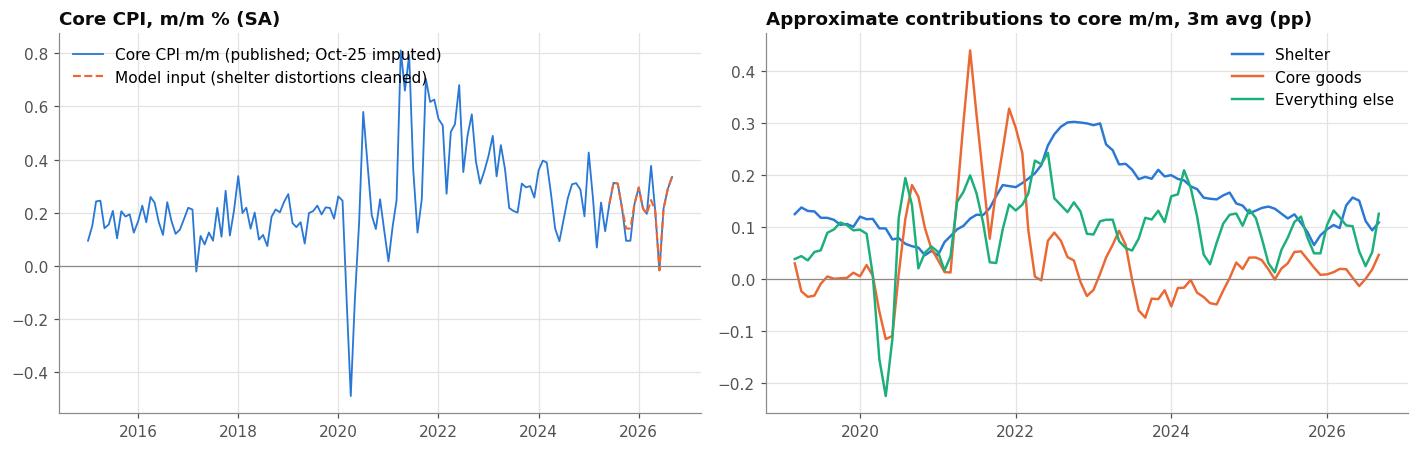

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
mm = y_actual.loc["2015":LAST_OBS]
ax.plot(mm.index, mm, color=PAL["blue"], lw=1.2, label="Core CPI m/m (published; Oct-25 imputed)")
if CLEAN_DISTORTIONS:
    cl = base["y"].loc["2025-06":LAST_OBS]
    ax.plot(cl.index, cl, color=PAL["orange"], ls="--", lw=1.4, label="Model input (shelter distortions cleaned)")
ax.axhline(0, color=PAL["muted"], lw=0.8)
ax.set_title("Core CPI, m/m % (SA)"); ax.legend(loc="upper left")
ax = axes[1]
contrib = pd.DataFrame({"Shelter": sum(SHELTER_SHARE_OF_CORE[b] * block_pub[b] for b in ("OER", "Rent")),
                        "Core goods": 0.25 * block_pub["Core goods"]}).loc["2019":LAST_OBS].rolling(3).mean()
contrib["Everything else"] = y_actual.loc["2019":LAST_OBS].rolling(3).mean() - contrib.sum(axis=1)
for col, c in zip(contrib.columns, (PAL["blue"], PAL["orange"], PAL["aqua"])):
    ax.plot(contrib.index, contrib[col], color=c, label=col)
ax.axhline(0, color=PAL["muted"], lw=0.8)
ax.set_title("Approximate contributions to core m/m, 3m avg (pp)"); ax.legend(loc="upper right")
for ax in axes:
    ax.xaxis.set_major_locator(mdates.YearLocator(2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout(); plt.show()

## 3. Model suite

| Family | Model | Notes |
|---|---|---|
| Time series | Random walk; 3-, 6- and 12-month mean | **3m mean** is the naive bar |
| Time series | **AR(p), BIC over p = 0..12**, expanding; AR rolling 10y; ARMA(1,1); local level | AR(BIC) is the *main benchmark* |
| Time series + exog | ARX-core: 3 own lags, OER 3m avg, Manheim (T..T−2), wage growth | OLS; also Huber-robust and discounted-LS (36m half-life) versions |
| Factor model | FAAR: 2 own lags plus 4 principal components of feature set A | |
| Machine learning | Ridge, Lasso, Random Forest, XGBoost on feature sets A and B | |
| Hybrid | ARX-core + XGB on its residuals (A); + RF on its residuals (B) | |
| Bottom-up | 9 blocks aggregated with constrained NNLS weights (last 60 months): (i) AR(BIC) per block; (ii) **tailored** block models; (iii) Ridge per block on own lags plus common indicators | |
| Combination | mean, median, 20%-trimmed mean, inverse-MSE (24m), top-5 (24m), NNLS stacking (36m) | |

**Tailored block models:**
* **OER:** ARX on 3 own lags, rent 6m avg, Case-Shiller and CPI ex-shelter (the OER notebook's winner).
* **Rent:** the same, with OER in place of rent.
* **Core goods:** ARX-Manheim (the core-goods notebook's winner).
* **Lodging:** 10-year mean (the lodging notebook's finding).
* **Transportation services:** ARX on own lags and jet fuel prices (airfares).
* **Other blocks:** AR(BIC).

In [6]:
def lagmat(y, p):
    Y = y[p:]
    return Y, np.column_stack([np.ones(len(Y))] + [y[p - j - 1:len(y) - j - 1] for j in range(p)])


def ar_bic(y, pmax=12, pmin=0):
    best = None
    for p in range(pmin, pmax + 1):
        Y, Z = lagmat(y[pmax - p:], p)
        b, *_ = np.linalg.lstsq(Z, Y, rcond=None)
        e = Y - Z @ b
        bic = len(Y) * np.log(e @ e / len(Y)) + (p + 1) * np.log(len(Y))
        if best is None or bic < best[0]:
            best = (bic, p)
    p = best[1]
    Y, Z = lagmat(y, p)
    b, *_ = np.linalg.lstsq(Z, Y, rcond=None)
    return b[0] + (b[1:] @ y[::-1][:p] if p else 0.0), Y - Z @ b, p


def ols_fit(Xtr, ytr, w=None):
    Z = np.column_stack([np.ones(len(Xtr)), Xtr])
    if w is not None:
        sw = np.sqrt(w); b, *_ = np.linalg.lstsq(Z * sw[:, None], ytr * sw, rcond=None)
    else:
        b, *_ = np.linalg.lstsq(Z, ytr, rcond=None)
    return b


def ols_fc(Xtr, ytr, xte, w=None):
    b = ols_fit(Xtr, ytr, w)
    return float(b[0] + np.asarray(xte, float) @ b[1:])


def make_ml(name):
    if name == "Ridge":
        return make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 40)))
    if name == "Lasso":
        return make_pipeline(StandardScaler(), LassoCV(alphas=np.logspace(-4, 0, 30), cv=TimeSeriesSplit(5), max_iter=20000))
    if name == "RF":
        return RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=0.33, random_state=SEED, n_jobs=-1)
    if name == "XGB":
        return XGBRegressor(n_estimators=300, max_depth=2, learning_rate=0.03, subsample=0.8, colsample_bytree=0.8,
                            min_child_weight=3, reg_lambda=2.0, random_state=SEED, n_jobs=4, verbosity=0)
    raise ValueError(name)


MODEL_FAMILY = {}
def fam(name, family):
    MODEL_FAMILY[name] = family
    return name


# ---------------- bottom-up machinery
def block_lag_frame(b, n=6):
    """Own-lag design for block b aligned to target months (inputs are the cleaned block series)."""
    return pd.concat({f"l{j+1}": block_in[b].shift(j + 1) for j in range(n)}, axis=1)


TAILORED = {   # block: list of extra features from X_all (own lags l1..l3 always included)
    "OER": [f"{bkey['Rent']}_ma6", "cs_yoy_s6", "exshelter_yoy"],
    "Rent": [f"{bkey['OER']}_ma6", "cs_yoy_s6", "exshelter_yoy"],
    "Core goods": ["mh_s0", "mh_s1", "mh_s2", "mh_s3", "ppi_l1"],
    "Transportation services": ["jet_s0", "jet_s1"],
}
BU_COMMON = ["mh_s0", "mh_s1", "mh_s2", "ppi_l1", "cs_yoy_s6", "ahe_yoy", "jet_s0", "exshelter_yoy"]


def bu_weights(T):
    win = block_pub.loc[:T - pd.offsets.MonthBegin(1)].join(y_actual.rename("agg")).dropna().iloc[-BU_WEIGHT_WINDOW:]
    win = win[~win.index.isin(pd.to_datetime(EXCLUDE_FROM_SCORE))]
    lam = 10.0
    w, _ = nnls(np.vstack([win[BLOCK_NAMES].values, lam * np.ones(len(BLOCK_NAMES))]), np.append(win["agg"].values, lam))
    return pd.Series(w, BLOCK_NAMES)


def block_forecasts(T, ok_cols):
    out = {}
    for b in BLOCK_NAMES:
        s = block_in[b].loc[TRAIN_START:T - pd.offsets.MonthBegin(1)].dropna()
        ar = ar_bic(s.values, pmax=6)[0]
        L = block_lag_frame(b)
        extra = [f for f in TAILORED.get(b, []) if f in ok_cols]
        common = [f for f in BU_COMMON if f in ok_cols]
        D = L.join(X_all[sorted(set(extra + common))])
        rows = D.index[(D.index >= TRAIN_START) & (D.index < T)]
        yb = block_in[b].reindex(rows)
        if b == "Lodging":
            tailored = s.iloc[-120:].mean()
        elif b in TAILORED:
            cols = ["l1", "l2", "l3"] + extra
            r_ = rows[D.loc[rows, cols].notna().all(axis=1).values & yb.notna().values]
            tailored = ols_fc(D.loc[r_, cols].values, yb[r_].values, D.loc[T, cols].values) if len(r_) >= MIN_TRAIN_OBS else ar
        else:
            tailored = ar
        cols = ["l1", "l2", "l3", "l4", "l5", "l6"] + common
        r_ = rows[D.loc[rows, cols].notna().all(axis=1).values & yb.notna().values]
        ridge = ar
        if len(r_) >= MIN_TRAIN_OBS and D.loc[[T], cols].notna().all(axis=1).iloc[0]:
            ridge = float(make_ml("Ridge").fit(D.loc[r_, cols], yb[r_]).predict(D.loc[[T], cols])[0])
        out[b] = {"AR": ar, "Tailored": tailored, "Ridge": ridge}
    return pd.DataFrame(out).T


def forecast_all(T, return_blocks=False):
    out = {}
    hist = y_train_series.loc[TRAIN_START:T - pd.offsets.MonthBegin(1)].dropna()
    y = hist.values
    out[fam("Random walk", "Time series")] = y[-1]
    out[fam("Mean 3m", "Time series")] = y[-3:].mean()
    out[fam("Mean 6m", "Time series")] = y[-6:].mean()
    out[fam("Mean 12m", "Time series")] = y[-12:].mean()
    out[fam("AR (BIC)", "Time series")] = ar_bic(y)[0]
    out[fam("AR (BIC, rolling 10y)", "Time series")] = ar_bic(y[-120:], pmax=6)[0]
    try:
        out[fam("ARMA(1,1)", "Time series")] = float(sm.tsa.SARIMAX(y, order=(1, 0, 1), trend="c").fit(disp=False).forecast(1)[0])
    except Exception:
        out["ARMA(1,1)"] = np.nan
    try:
        out[fam("Local level (UC)", "Time series")] = float(sm.tsa.UnobservedComponents(y, level="llevel").fit(disp=False).forecast(1)[0])
    except Exception:
        out["Local level (UC)"] = np.nan

    ok_cols = set(c for c in FEAT_B if pd.notna(X_all.loc[T, c]))
    fA = [c for c in FEAT_A if c in ok_cols]
    fB = [c for c in FEAT_B if c in ok_cols]
    aC = [c for c in ARX_CORE if c in ok_cols]
    rows = X_all.index[(X_all.index >= TRAIN_START) & (X_all.index < T)]
    ytr = y_train_series.reindex(rows)
    yok = ytr.notna().values
    trA = rows[X_all.loc[rows, fA].notna().all(axis=1).values & yok]
    trB = rows[X_all.loc[rows, fB].notna().all(axis=1).values & yok]
    trC = rows[X_all.loc[rows, aC].notna().all(axis=1).values & yok]
    xA, xB = X_all.loc[[T], fA], X_all.loc[[T], fB]
    canB = len(trB) >= MIN_TRAIN_OBS and "al_yoy_s0" in ok_cols

    XC, yC, xC = X_all.loc[trC, aC].values, ytr[trC].values, X_all.loc[T, aC].values
    out[fam("ARX-core", "Time series")] = ols_fc(XC, yC, xC)
    age = np.array([(T.year - t.year) * 12 + (T.month - t.month) for t in trC])
    out[fam("ARX-core (discounted LS)", "Time series")] = ols_fc(XC, yC, xC, w=0.5 ** (age / HALF_LIFE))
    hub = make_pipeline(StandardScaler(), HuberRegressor(epsilon=1.35, alpha=1e-4, max_iter=2000)).fit(XC, yC)
    out[fam("ARX-core (Huber)", "Time series")] = float(hub.predict(xC[None, :])[0])

    sc = StandardScaler().fit(X_all.loc[trA, fA])
    Ztr, zT = sc.transform(X_all.loc[trA, fA]), sc.transform(xA)
    _, _, Vt = np.linalg.svd(Ztr, full_matrices=False)
    Ftr, fT = Ztr @ Vt[:N_FACTORS].T, zT @ Vt[:N_FACTORS].T
    out[fam("FAAR (4 factors)", "Time series")] = ols_fc(np.column_stack([X_all.loc[trA, ["y_l1", "y_l2"]].values, Ftr]),
                                                        ytr[trA].values, np.append(X_all.loc[T, ["y_l1", "y_l2"]].values, fT[0]))

    for mname in ("Ridge", "Lasso", "RF", "XGB"):
        out[fam(f"{mname}-A", "Machine learning")] = float(make_ml(mname).fit(X_all.loc[trA, fA], ytr[trA]).predict(xA)[0])
        out[fam(f"{mname}-B", "Machine learning")] = (float(make_ml(mname).fit(X_all.loc[trB, fB], ytr[trB]).predict(xB)[0])
                                                      if canB else np.nan)

    bC = ols_fit(XC, yC)
    res = pd.Series(yC - np.column_stack([np.ones(len(XC)), XC]) @ bC, index=trC)
    rA = trA.intersection(res.index)
    out[fam("ARX-core + XGB resid (A)", "Hybrid")] = out["ARX-core"] + float(make_ml("XGB").fit(X_all.loc[rA, fA], res[rA]).predict(xA)[0])
    rB = trB.intersection(res.index)
    out[fam("ARX-core + RF resid (B)", "Hybrid")] = (out["ARX-core"] + float(make_ml("RF").fit(X_all.loc[rB, fB], res[rB]).predict(xB)[0])
                                                     if canB else np.nan)

    w = bu_weights(T)
    bf = block_forecasts(T, ok_cols)
    out[fam("Bottom-up: AR blocks", "Bottom-up")] = float(w @ bf["AR"])
    out[fam("Bottom-up: tailored blocks", "Bottom-up")] = float(w @ bf["Tailored"])
    out[fam("Bottom-up: Ridge blocks", "Bottom-up")] = float(w @ bf["Ridge"])
    if return_blocks:
        return out, bf.assign(weight=w)
    return out

## 4. Recursive pseudo-out-of-sample backtest
Every model is re-estimated each month on data before the target month. This takes about 15–20 minutes.

In [7]:
targets = pd.date_range(BACKTEST_START, LAST_OBS, freq="MS")
t0 = time.time()
fc_rows = {}
for i, T in enumerate(targets):
    fc_rows[T] = forecast_all(T)
    if (i + 1) % 24 == 0:
        print(f"  {T:%Y-%m} done  ({time.time()-t0:.0f}s)")
fc = pd.DataFrame(fc_rows).T
print(f"Backtest: {len(targets)} targets x {fc.shape[1]} base models in {time.time()-t0:.0f}s")

  2015-12 done  (45s)


  2017-12 done  (93s)


  2019-12 done  (139s)


  2021-12 done  (204s)


  2023-12 done  (301s)


  2025-12 done  (398s)


Backtest: 153 targets x 25 base models in 436s


In [8]:
excl = pd.to_datetime(EXCLUDE_FROM_SCORE)
err = fc.sub(y_actual.reindex(fc.index), axis=0)
err_ok = err[~err.index.isin(excl)]


def combine(T, fc_row, err_hist, fc_hist):
    prev = T - pd.offsets.MonthBegin(1)
    past = err_hist.loc[:prev].iloc[-COMBO_LOOKBACK:]
    avail_m = fc_row.dropna().index
    mse = (past[avail_m] ** 2).mean()
    mse = mse[past[avail_m].notna().sum() >= 6]
    out = {"Combo: mean (all)": fc_row[avail_m].mean(), "Combo: median (all)": fc_row[avail_m].median(),
           "Combo: trimmed mean (20%)": stats.trim_mean(fc_row[avail_m].values, 0.2)}
    if len(mse) >= 3:
        w = (1 / mse) / (1 / mse).sum()
        out["Combo: inverse-MSE"] = float((fc_row[w.index] * w).sum())
        out["Combo: top-5 trailing"] = fc_row[mse.nsmallest(5).index].mean()
    else:
        out["Combo: inverse-MSE"] = out["Combo: top-5 trailing"] = out["Combo: mean (all)"]
    hist_f = fc_hist.loc[:prev]
    hist_f = hist_f[~hist_f.index.isin(excl)].iloc[-STACK_LOOKBACK:]
    cols = [m for m in avail_m if len(hist_f) and hist_f[m].notna().all()]
    if len(hist_f) >= 18 and len(cols) >= 3:
        lam = 10.0
        wts, _ = nnls(np.vstack([hist_f[cols].values, lam * np.ones(len(cols))]),
                      np.append(y_actual.reindex(hist_f.index).values, lam))
        wts = wts / wts.sum() if wts.sum() > 0 else np.ones(len(cols)) / len(cols)
        out["Combo: NNLS stacking"] = float(fc_row[cols].values @ wts)
    else:
        out["Combo: NNLS stacking"] = out["Combo: mean (all)"]
    return out


combo = pd.DataFrame({T: combine(T, fc.loc[T], err_ok, fc) for T in fc.index}).T
for c in combo.columns:
    MODEL_FAMILY[c] = "Combination"
fc_full = pd.concat([fc, combo], axis=1)

## 5. Out-of-sample evaluation
Oct and Nov 2025 are excluded throughout. DM p-values come from two-sided HLN-corrected Diebold–Mariano
tests (squared loss) against AR(BIC) and against the 3-month mean.
* **Table 1:** long-history models, 2015+.
* **Table 2:** all models including market-rent (B) models, 2021+.

In [9]:
def dm_test(e1, e2):
    d = e1 ** 2 - e2 ** 2
    d = d[~np.isnan(d)]
    n = len(d)
    if n < 10 or np.allclose(d, 0):
        return np.nan, np.nan
    stat = d.mean() / np.sqrt(d.var(ddof=0) / n) * np.sqrt((n - 1) / n)
    return stat, 2 * stats.t.sf(abs(stat), df=n - 1)


def evaluate(fcs, actual, mask, models=None):
    models = models or list(fcs.columns)
    a = actual.reindex(fcs.index)[mask]
    f = fcs.loc[mask, models]
    e = f.sub(a, axis=0)
    rows = {}
    for m in models:
        em = e[m]; ok = em.notna()
        if ok.sum() == 0:
            continue
        rmse = np.sqrt((em[ok] ** 2).mean())
        st, p = dm_test(em.values, e[BENCH].values) if m != BENCH else (np.nan, np.nan)
        _, pn = dm_test(em.values, e[NAIVE].values) if m != NAIVE else (np.nan, np.nan)
        rows[m] = {"family": MODEL_FAMILY.get(m, ""), "N": ok.sum(), "RMSE": rmse, "MAE": em[ok].abs().mean(),
                   "Bias": em[ok].mean(), "Rel RMSE vs AR": rmse / np.sqrt((e[BENCH][ok] ** 2).mean()),
                   "DM stat": st, "DM p": p, f"DM p vs {NAIVE}": pn,
                   "Hit 0.1pp": (f[m][ok].round(1) == a[ok].round(1)).mean()}
    if not rows:
        return pd.DataFrame(columns=["family", "N", "RMSE", "MAE"])
    return pd.DataFrame(rows).T.sort_values("RMSE")


fmt = {"RMSE": "{:.3f}", "MAE": "{:.3f}", "Bias": "{:+.3f}", "Rel RMSE vs AR": "{:.3f}", "DM stat": "{:+.2f}",
       "DM p": "{:.3f}", f"DM p vs {NAIVE}": "{:.3f}", "Hit 0.1pp": "{:.0%}"}
not_excl = pd.Series(~fc_full.index.isin(excl), index=fc_full.index)
B_MODELS = [m for m in fc_full.columns if m.endswith("-B") or "(B)" in m]
long_models = [m for m in fc_full.columns if m not in B_MODELS]
w15 = not_excl & (fc_full.index >= SCORE_START)
w21 = not_excl & (fc_full.index >= SCORE_START_ALL)
results15 = evaluate(fc_full, y_actual, w15, long_models)
results21 = evaluate(fc_full, y_actual, w21)
print(f"Table 1 — long-history models, {SCORE_START[:7]} to {LAST_OBS:%Y-%m} (N = {int(w15.sum())})")
results15.style.format(fmt).background_gradient(subset=["Rel RMSE vs AR"], cmap="RdYlGn_r", vmin=0.7, vmax=1.3)

Table 1 — long-history models, 2015-01 to 2026-09 (N = 139)


,family,N,RMSE,MAE,Bias,Rel RMSE vs AR,DM stat,DM p,DM p vs Mean 3m,Hit 0.1pp
Bottom-up: tailored blocks,Bottom-up,139,0.117,0.079,-0.020,0.843,-2.37,0.019,0.007,47%
ARX-core + XGB resid (A),Hybrid,139,0.122,0.087,-0.015,0.884,-1.85,0.067,0.011,43%
Bottom-up: Ridge blocks,Bottom-up,139,0.123,0.084,-0.027,0.888,-1.89,0.061,0.009,45%
Combo: NNLS stacking,Combination,139,0.124,0.084,-0.015,0.894,-1.76,0.080,0.012,40%
Combo: top-5 trailing,Combination,139,0.124,0.085,-0.017,0.898,-1.97,0.051,0.008,42%
Combo: inverse-MSE,Combination,139,0.124,0.083,-0.018,0.899,-2.45,0.015,0.005,45%
Combo: mean (all),Combination,139,0.125,0.084,-0.018,0.900,-2.48,0.014,0.004,43%
Combo: trimmed mean (20%),Combination,139,0.126,0.084,-0.020,0.909,-2.32,0.022,0.005,45%
Combo: median (all),Combination,139,0.126,0.083,-0.020,0.910,-2.36,0.020,0.005,46%
FAAR (4 factors),Time series,139,0.126,0.085,-0.017,0.913,-1.86,0.065,0.020,44%


In [10]:
print(f"Table 2 — all models, {SCORE_START_ALL[:7]} to {LAST_OBS:%Y-%m} (N = {int(w21.sum())})")
results21.style.format(fmt).background_gradient(subset=["Rel RMSE vs AR"], cmap="RdYlGn_r", vmin=0.7, vmax=1.3)

Table 2 — all models, 2021-01 to 2026-09 (N = 67)


,family,N,RMSE,MAE,Bias,Rel RMSE vs AR,DM stat,DM p,DM p vs Mean 3m,Hit 0.1pp
ARX-core + XGB resid (A),Hybrid,67,0.132,0.101,-0.029,0.809,-2.06,0.044,0.038,36%
ARX-core + RF resid (B),Hybrid,67,0.135,0.105,-0.030,0.828,-1.86,0.067,0.051,33%
Bottom-up: tailored blocks,Bottom-up,67,0.135,0.097,-0.051,0.831,-1.99,0.050,0.026,39%
Bottom-up: Ridge blocks,Bottom-up,67,0.135,0.103,-0.056,0.832,-2.02,0.048,0.033,30%
Combo: NNLS stacking,Combination,67,0.137,0.101,-0.034,0.843,-2.07,0.043,0.021,25%
Combo: top-5 trailing,Combination,67,0.138,0.103,-0.031,0.848,-2.06,0.043,0.030,31%
Combo: inverse-MSE,Combination,67,0.138,0.102,-0.036,0.850,-2.52,0.014,0.021,33%
Combo: mean (all),Combination,67,0.138,0.102,-0.036,0.851,-2.56,0.013,0.020,31%
Combo: trimmed mean (20%),Combination,67,0.140,0.102,-0.039,0.860,-2.49,0.015,0.025,33%
Ridge-A,Machine learning,67,0.140,0.100,-0.012,0.861,-1.51,0.135,0.071,37%


### Robustness and choice of headline model
Sub-period RMSEs follow. The **headline model** is the long-history model with the lowest *average relative
RMSE across the four sub-periods*, where relative means its RMSE divided by the best RMSE in that period.
This rewards models that are good in every regime, not just in the period that dominates the full-sample RMSE.

In [11]:
periods = {"2015–19": ("2015-01", "2019-12"), "2020–22": ("2020-01", "2022-12"),
           "2023–24": ("2023-01", "2024-12"), "2025–26": ("2025-01", str(LAST_OBS.date()))}
sub = {}
for lab, (a, b) in periods.items():
    sub[f"RMSE {lab}"] = evaluate(fc_full, y_actual, not_excl & (fc_full.index >= a) & (fc_full.index <= b))["RMSE"]
sub["RMSE ex Apr-26"] = evaluate(fc_full, y_actual, w15 & (fc_full.index != "2026-04-01"), long_models)["RMSE"]
sub[f"RMSE {BAND_START[:4]}+"] = evaluate(fc_full, y_actual, not_excl & (fc_full.index >= BAND_START))["RMSE"]
robust = pd.DataFrame(sub).reindex(results21.index).astype(float)
per_cols = [f"RMSE {k}" for k in periods]
robust["robustness score"] = (robust[per_cols] / robust[per_cols].min()).mean(axis=1, skipna=False)   # needs all 4 periods
robust.insert(0, "family", results21["family"])
robust = robust.sort_values("robustness score")
HEADLINE_MODEL = robust["robustness score"].dropna().index[0]
print("Headline model (most robust across sub-periods):", HEADLINE_MODEL)
robust.style.format({c: "{:.3f}" for c in robust.columns if c != "family"}, na_rep="–").background_gradient(
    subset=[c for c in robust.columns if c != "family"], cmap="RdYlGn_r", axis=0)

Headline model (most robust across sub-periods): Bottom-up: tailored blocks


,family,RMSE 2015–19,RMSE 2020–22,RMSE 2023–24,RMSE 2025–26,RMSE ex Apr-26,RMSE 2023+,robustness score
Bottom-up: tailored blocks,Bottom-up,0.062,0.195,0.076,0.093,0.117,0.084,1.071
Combo: median (all),Combination,0.062,0.215,0.065,0.106,0.126,0.085,1.092
Combo: trimmed mean (20%),Combination,0.062,0.214,0.067,0.105,0.126,0.086,1.100
Combo: mean (all),Combination,0.063,0.211,0.069,0.104,0.124,0.087,1.102
Combo: inverse-MSE,Combination,0.063,0.210,0.070,0.104,0.124,0.087,1.105
Bottom-up: AR blocks,Bottom-up,0.060,0.218,0.071,0.104,0.127,0.087,1.110
Combo: NNLS stacking,Combination,0.062,0.209,0.076,0.100,0.124,0.088,1.113
FAAR (4 factors),Time series,0.062,0.215,0.073,0.101,0.127,0.087,1.113
Lasso-A,Machine learning,0.066,0.225,0.069,0.098,0.130,0.083,1.118
Ridge-A,Machine learning,0.065,0.214,0.074,0.100,0.126,0.086,1.124


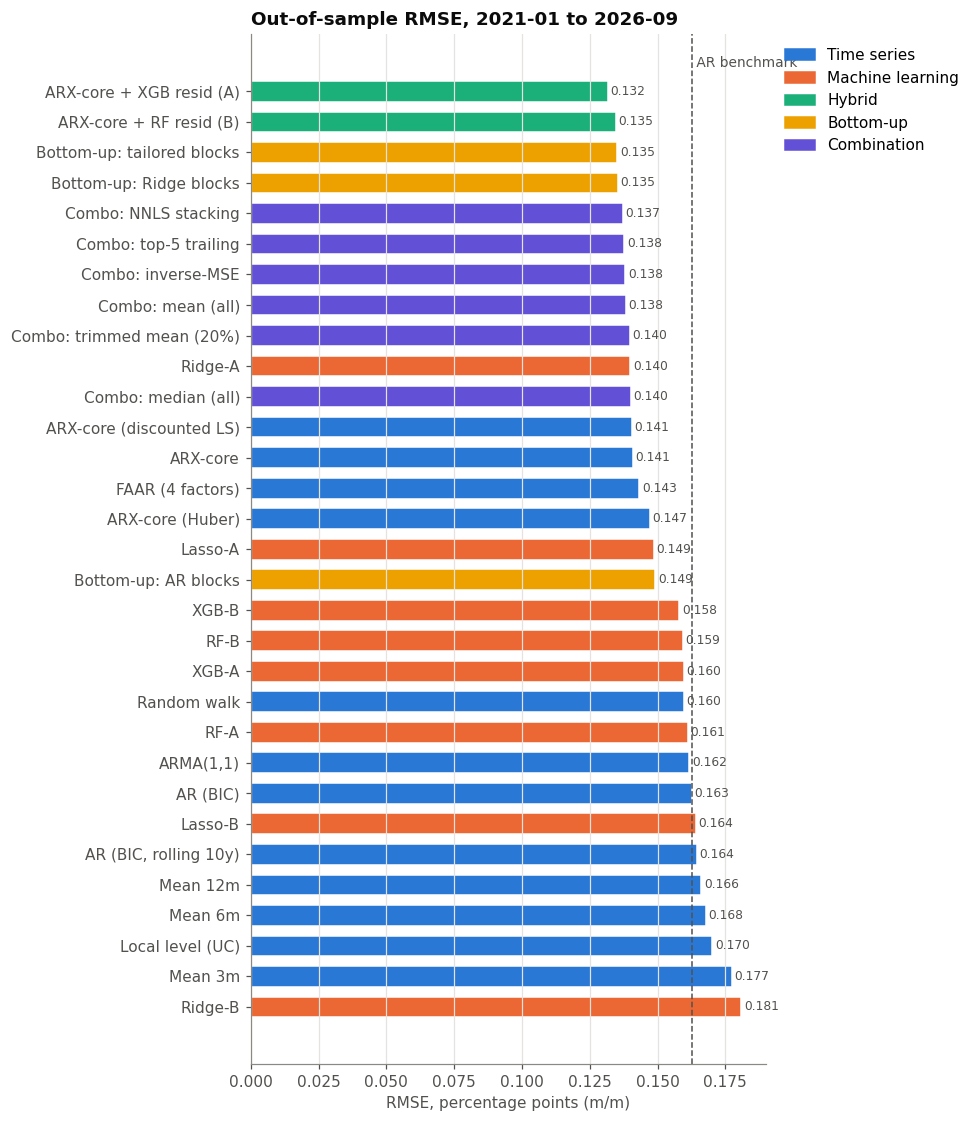

In [12]:
r = results21.sort_values("RMSE")
fig, ax = plt.subplots(figsize=(9, 0.3 * len(r) + 1))
ypos = np.arange(len(r))[::-1]
ax.barh(ypos, r["RMSE"], height=0.68, color=[FAMILY_COLOR[f] for f in r["family"]], edgecolor="white", linewidth=1)
ax.axvline(r.loc[BENCH, "RMSE"], color=PAL["ink2"], lw=1, ls="--")
ax.text(r.loc[BENCH, "RMSE"], len(r) - 0.3, " AR benchmark", color=PAL["ink2"], fontsize=9, va="bottom")
ax.set_yticks(ypos); ax.set_yticklabels(r.index)
for yv, v in zip(ypos, r["RMSE"]):
    ax.text(v + 0.001, yv, f"{v:.3f}", va="center", fontsize=8, color=PAL["ink2"])
ax.grid(axis="y", visible=False)
ax.set_xlabel("RMSE, percentage points (m/m)")
ax.set_title(f"Out-of-sample RMSE, {SCORE_START_ALL[:7]} to {LAST_OBS:%Y-%m}")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in FAMILY_COLOR.values()]
ax.legend(handles, FAMILY_COLOR.keys(), loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout(); plt.show()

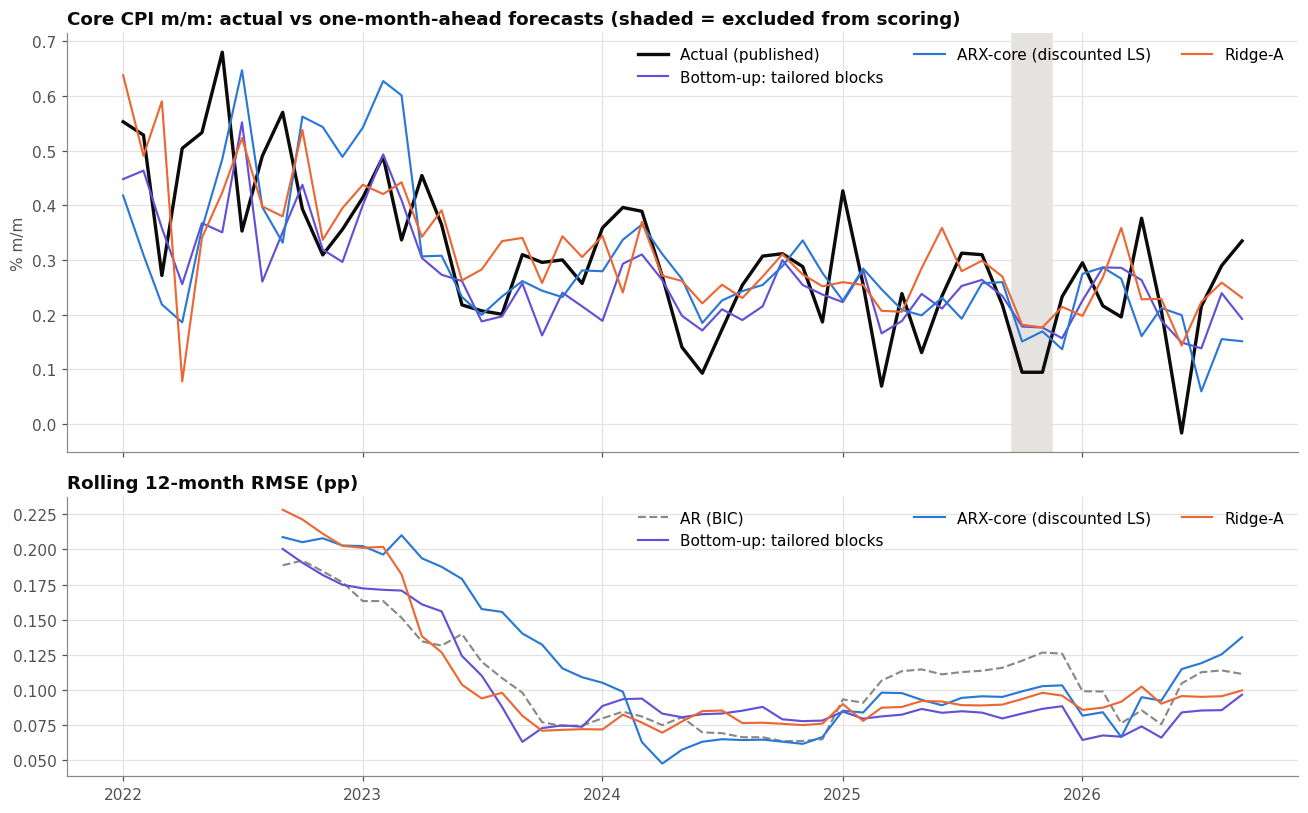

In [13]:
best = {f: results21[results21.family == f].index[0] for f in FAMILY_COLOR if (results21.family == f).any()}
show = [(HEADLINE_MODEL, PAL["violet"])] + [(best[f], FAMILY_COLOR[f]) for f in ("Time series", "Machine learning", "Bottom-up")
                                             if f in best and best[f] != HEADLINE_MODEL]
w = fc_full.loc["2022-01-01":]
act = y_actual.loc["2022-01-01":LAST_OBS]
fig, axes = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
ax = axes[0]
ax.plot(act.index, act, color=PAL["ink"], lw=2.2, label="Actual (published)")
for m, c in show:
    ax.plot(w.index, w[m], color=c, lw=1.4, label=m)
for d in EXCLUDE_FROM_SCORE:
    ax.axvspan(pd.Timestamp(d) - pd.Timedelta(days=15), pd.Timestamp(d) + pd.Timedelta(days=15), color=PAL["grid"], zorder=0)
ax.set_title("Core CPI m/m: actual vs one-month-ahead forecasts (shaded = excluded from scoring)")
ax.set_ylabel("% m/m"); ax.legend(ncol=3, loc="upper right")
ax = axes[1]
for m, c in [(BENCH, PAL["muted"])] + show:
    e2 = (w[m] - y_actual.reindex(w.index)) ** 2
    e2[w.index.isin(excl)] = np.nan
    ax.plot(w.index, np.sqrt(e2.rolling(12, min_periods=9).mean()), color=c, lw=1.4, ls="--" if m == BENCH else "-", label=m)
ax.set_title("Rolling 12-month RMSE (pp)"); ax.legend(ncol=3, loc="upper right")
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout(); plt.show()

## 6. What drives the models? (final fit)

In [14]:
trC = X_all.index[X_all[ARX_CORE].notna().all(axis=1) & y_train_series.reindex(X_all.index).notna()
                  & (X_all.index >= TRAIN_START) & (X_all.index < TARGET_MONTH)]
ols = sm.OLS(y_train_series[trC], sm.add_constant(X_all.loc[trC, ARX_CORE])).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
print("ARX-core, full-sample OLS with HAC standard errors:"); print(ols.summary().tables[1])
rowsA = X_all.index[okA & y_train_series.reindex(X_all.index).notna() & (X_all.index >= TRAIN_START) & (X_all.index < TARGET_MONTH)]
lasA = make_ml("Lasso").fit(X_all.loc[rowsA, FEAT_A], y_train_series[rowsA])
coefA = pd.Series(lasA[-1].coef_, FEAT_A)
print("\nLasso-A non-zero standardized coefficients:\n", coefA[coefA != 0].sort_values(key=abs, ascending=False).round(4).to_string())
print("\nBottom-up aggregation weights (latest):\n", bu_weights(TARGET_MONTH).round(3).to_string())

ARX-core, full-sample OLS with HAC standard errors:
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0253      0.021      1.193      0.233      -0.016       0.067
y_l1           0.4869      0.074      6.605      0.000       0.342       0.631
y_l2           0.1244      0.100      1.239      0.215      -0.072       0.321
y_l3          -0.0721      0.076     -0.950      0.342      -0.221       0.077
b_oer_ma3      0.3038      0.069      4.430      0.000       0.169       0.438
mh_s0          0.0218      0.007      3.357      0.001       0.009       0.035
mh_s1          0.0065      0.004      1.699      0.089      -0.001       0.014
mh_s2          0.0039      0.004      1.040      0.298      -0.003       0.011
ahe_yoy       -0.0052      0.011     -0.462      0.644      -0.027       0.017

Lasso-A non-zero standardized coefficients:
 unrate_d12                     -0

## 7. Next-month forecast

In [15]:
live, blocks_live = forecast_all(TARGET_MONTH, return_blocks=True)
live = pd.Series(live)
live_all = pd.concat([live, pd.Series(combine(TARGET_MONTH, live, err_ok, fc))])
rmse_recent = robust[f"RMSE {BAND_START[:4]}+"]
last_idx = data.loc[LAST_OBS, "core"]
tbl = pd.DataFrame({"family": [MODEL_FAMILY.get(m, "") for m in live_all.index],
                    "forecast m/m %": live_all.values,
                    "robustness score": robust["robustness score"].reindex(live_all.index).values,
                    "RMSE 2021+": results21["RMSE"].reindex(live_all.index).values,
                    f"RMSE {BAND_START[:4]}+": rmse_recent.reindex(live_all.index).values}, index=live_all.index)
tbl["implied index"] = last_idx * (1 + tbl["forecast m/m %"] / 100)
yr_ago = data.loc[TARGET_MONTH - pd.DateOffset(years=1), "core"]
tbl["implied y/y %"] = 100 * (tbl["implied index"] / yr_ago - 1)
tbl = tbl.sort_values("robustness score")

h_fc, h_rmse = tbl.loc[HEADLINE_MODEL, "forecast m/m %"], tbl.loc[HEADLINE_MODEL, f"RMSE {BAND_START[:4]}+"]
print(f"Core CPI forecast for {TARGET_MONTH:%B %Y}" + ("  (Manheim mid-month proxy used)" if MH_PROXY_USED else ""))
print(f"  Headline ({HEADLINE_MODEL}): {h_fc:+.3f}% m/m  [90% band, {BAND_START[:4]}+ errors: "
      f"{h_fc-1.645*h_rmse:+.2f} to {h_fc+1.645*h_rmse:+.2f}]  -> rounds to {h_fc:+.1f}%;  implied y/y {tbl.loc[HEADLINE_MODEL,'implied y/y %']:.2f}%")
print(f"  Range across all models: {live_all.min():+.3f} to {live_all.max():+.3f}; median {live_all.median():+.3f}")
print(f"  Last print ({LAST_OBS:%b %Y}): {y_actual[LAST_OBS]:+.3f}%   3m avg: {y_actual.loc[:LAST_OBS].iloc[-3:].mean():+.3f}%")
edges = np.arange(-0.25, 0.75, 0.1)
probs = pd.Series(np.diff(stats.norm.cdf(edges, h_fc, h_rmse)), index=np.round(edges[:-1] + 0.05, 1))
print("  Probability of each rounded print:", {f"{k:+.1f}": f"{v:.0%}" for k, v in probs.items() if v >= 0.02})
tbl.style.format({"forecast m/m %": "{:+.3f}", "robustness score": "{:.3f}", "RMSE 2021+": "{:.3f}",
                  f"RMSE {BAND_START[:4]}+": "{:.3f}", "implied index": "{:.3f}", "implied y/y %": "{:+.2f}"})

Core CPI forecast for October 2026  (Manheim mid-month proxy used)
  Headline (Bottom-up: tailored blocks): +0.235% m/m  [90% band, 2023+ errors: +0.10 to +0.37]  -> rounds to +0.2%;  implied y/y 2.71%
  Range across all models: +0.208 to +0.335; median +0.250
  Last print (Sep 2026): +0.335%   3m avg: +0.280%
  Probability of each rounded print: {'+0.1': '14%', '+0.2': '42%', '+0.3': '34%', '+0.4': '8%'}


,family,forecast m/m %,robustness score,RMSE 2021+,RMSE 2023+,implied index,implied y/y %
Bottom-up: tailored blocks,Bottom-up,+0.235,1.071,0.135,0.084,339.692,+2.71
Combo: median (all),Combination,+0.249,1.092,0.140,0.085,339.741,+2.72
Combo: trimmed mean (20%),Combination,+0.250,1.100,0.140,0.086,339.745,+2.73
Combo: mean (all),Combination,+0.253,1.102,0.138,0.087,339.753,+2.73
Combo: inverse-MSE,Combination,+0.250,1.105,0.138,0.087,339.744,+2.73
Bottom-up: AR blocks,Bottom-up,+0.232,1.110,0.149,0.087,339.684,+2.71
Combo: NNLS stacking,Combination,+0.244,1.113,0.137,0.088,339.723,+2.72
FAAR (4 factors),Time series,+0.294,1.113,0.143,0.087,339.893,+2.77
Lasso-A,Machine learning,+0.255,1.118,0.149,0.083,339.760,+2.73
Ridge-A,Machine learning,+0.257,1.124,0.140,0.086,339.766,+2.73


In [16]:
# Block view of the bottom-up forecast: contribution = weight x block forecast
bv = blocks_live.copy()
bv["last print"] = block_pub.loc[LAST_OBS]
bv["contribution (tailored)"] = bv["weight"] * bv["Tailored"]
bv["contribution (Ridge)"] = bv["weight"] * bv["Ridge"]
bv.loc["Total"] = pd.Series({c: bv[c].sum() if c.startswith(("weight", "contribution")) else np.nan for c in bv.columns})
bv.style.format("{:+.3f}", na_rep="")

,AR,Tailored,Ridge,weight,last print,contribution (tailored),contribution (Ridge)
OER,+0.264,+0.255,+0.260,+0.389,+0.350,+0.099,+0.101
Rent,+0.218,+0.248,+0.240,+0.063,+0.247,+0.015,+0.015
Lodging,+0.187,+0.192,-0.044,+0.015,+2.035,+0.003,-0.001
Core goods,+0.140,+0.111,+0.124,+0.261,+0.251,+0.029,+0.032
Medical services,+0.278,+0.278,+0.299,+0.080,+0.284,+0.022,+0.024
Transportation services,+0.403,+0.579,+0.257,+0.066,+0.585,+0.038,+0.017
Water/sewer/trash,+0.378,+0.378,+0.354,+0.033,+0.231,+0.012,+0.012
Educ. & comm. services,+0.126,+0.126,+0.122,+0.061,+0.047,+0.008,+0.007
Recreation services,+0.233,+0.233,+0.307,+0.031,+0.298,+0.007,+0.010
Total,,,,+1.000,,+0.235,+0.218


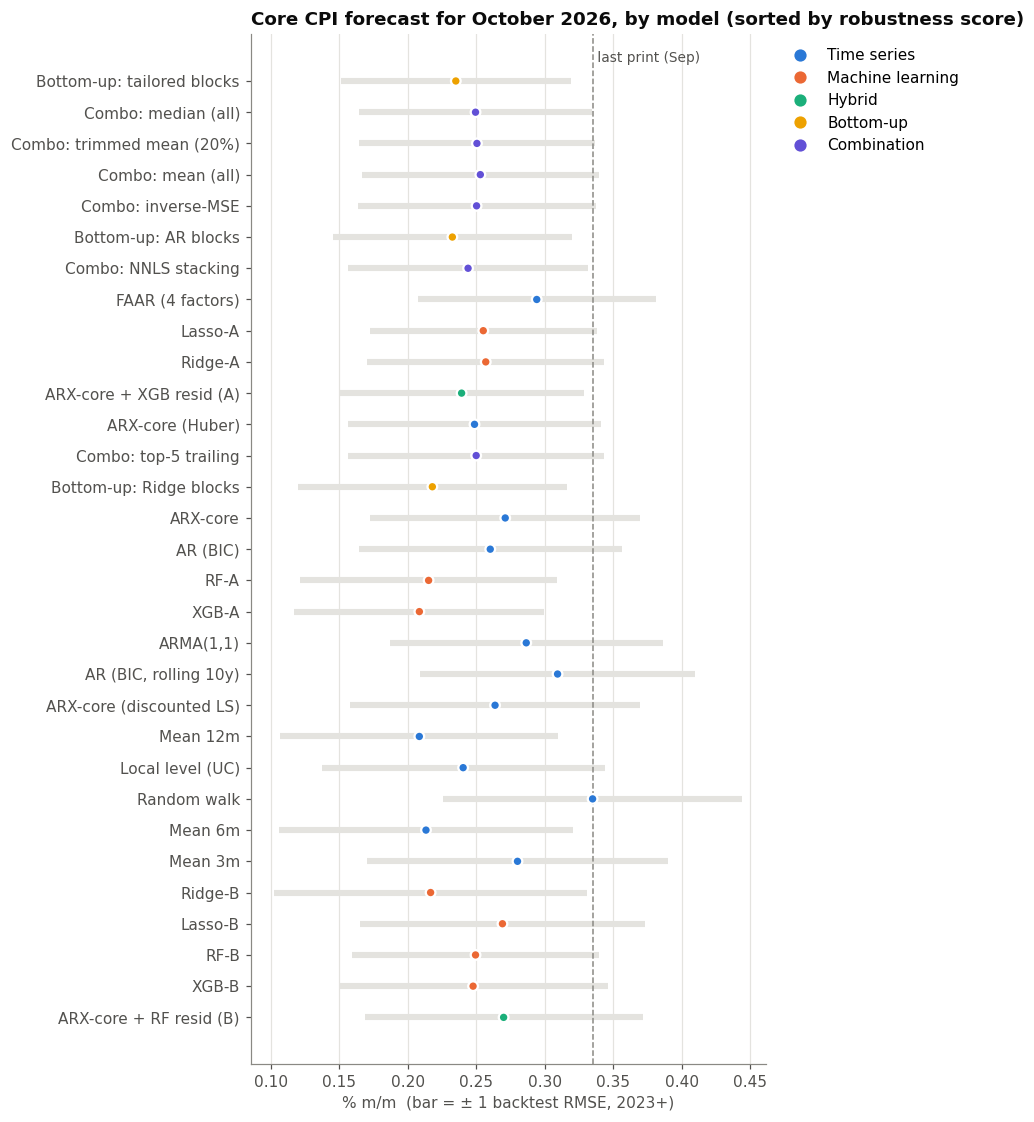

In [17]:
fig, ax = plt.subplots(figsize=(9, 0.3 * len(tbl) + 1))
ypos = np.arange(len(tbl))[::-1]
band = tbl[f"RMSE {BAND_START[:4]}+"]
ax.hlines(ypos, tbl["forecast m/m %"] - band, tbl["forecast m/m %"] + band, color=PAL["grid"], lw=4)
ax.scatter(tbl["forecast m/m %"], ypos, s=40, color=[FAMILY_COLOR[f] for f in tbl["family"]], edgecolor="white", linewidth=1.5, zorder=3)
ax.axvline(y_actual[LAST_OBS], color=PAL["muted"], ls="--", lw=1)
ax.text(y_actual[LAST_OBS], len(tbl) - 0.4, f" last print ({LAST_OBS:%b})", color=PAL["ink2"], fontsize=9)
ax.set_yticks(ypos); ax.set_yticklabels(tbl.index); ax.grid(axis="y", visible=False)
ax.set_xlabel(f"% m/m  (bar = ± 1 backtest RMSE, {BAND_START[:4]}+)")
ax.set_title(f"Core CPI forecast for {TARGET_MONTH:%B %Y}, by model (sorted by robustness score)")
handles = [plt.Line2D([], [], marker="o", ls="", color=c, markersize=7) for c in FAMILY_COLOR.values()]
ax.legend(handles, FAMILY_COLOR.keys(), loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout(); plt.show()

In [18]:
os.makedirs("outputs", exist_ok=True)
pd.concat([y_actual.rename("actual_published").reindex(fc_full.index), fc_full], axis=1).to_csv("outputs/corecpi_backtest_forecasts.csv")
results15.to_csv("outputs/corecpi_backtest_scores_2015.csv")
results21.to_csv("outputs/corecpi_backtest_scores_2021.csv")
robust.to_csv("outputs/corecpi_robustness.csv")
tbl.to_csv(f"outputs/corecpi_forecast_{TARGET_MONTH:%Y_%m}.csv")
bv.to_csv(f"outputs/corecpi_blocks_{TARGET_MONTH:%Y_%m}.csv")
print("Saved to ./outputs/")

Saved to ./outputs/


## 8. Findings (run of 6 Nov 2026; data through Sep 2026 CPI, Manheim through mid-Oct 2026, Oct jobs report not yet on FRED)

* **Bottom-up with tailored block models is the best and most robust approach for core CPI.** Each block
  gets the model that won in its own notebook:
  * **OER and rent:** ARX on shelter fundamentals.
  * **Core goods:** ARX-Manheim.
  * **Lodging:** its long-run mean.
  * **Transportation services:** jet fuel.
  * **Other blocks:** AR.

  Aggregated with constrained NNLS weights, it scores:
  * 2015+: RMSE **0.117 pp**, **16% below AR(BIC)** (DM p = 0.02) and 29% below the 3-month mean (p = 0.007).
  * It hits the rounded print **48%** of the time.
  * It has the best robustness score: within about 7% of the best model in every sub-period.
* **Disaggregation helps when the block models are informative.** Bottom-up with plain AR blocks is only
  8% better than AR on the aggregate. Using the right indicator for each block (shelter fundamentals,
  Manheim, jet fuel) roughly doubles the gain.
* **Since 2021, the ARX-core + XGB-residual hybrid is marginally best** (0.132 vs 0.135 for tailored
  bottom-up). The difference is not meaningful, and the hybrid is weaker in 2015–19.
* **Combinations are close behind** (0.124–0.126 since 2015). The median combination is the second most
  robust model and a good cross-check.
* **Pure ML adds little.** Ridge-A and Lasso-A sit around AR minus 10%. Random Forest and XGBoost on their
  own are no better than AR. The short-history market-rent (B) models do not help at one month.
* **Errors by regime:**

  | Period | Best RMSE |
  |---|---|
  | 2015–19 | about 0.06 pp |
  | 2020–22 | about 0.20 pp |
  | 2023–24 | about 0.07 pp |
  | 2025–26 | about 0.09–0.10 pp |

  2025–26 is inflated by the shutdown distortions; April 2026's shelter catch-up is the largest miss.
* **October 2026:**
  * The headline (tailored bottom-up) is **+0.235% m/m**, which rounds to +0.2%. Implied y/y is 2.71%.
  * The models range from +0.21% to +0.34%; the median combination is +0.25%.
  * By contribution:
    * **OER:** +0.10 pp (0.26% m/m).
    * **Transportation services:** +0.04 pp, with a 0.58% jump driven by jet fuel.
    * **Core goods:** +0.03 pp (0.11%, as used-car prices cool).
    * **Medical services:** +0.02 pp.
    * **Rent:** +0.015 pp.
  * The forecast is close to the 0.25 rounding boundary. Rough odds: **0.2% about 42%**, 0.3% about 34%,
    0.1% about 14%, 0.4% about 8%.
  * Re-run after (i) today's October jobs report reaches FRED, which adds wages and unemployment, and
    (ii) Cox's full-October Manheim release, which replaces the mid-month proxy.
